# 08. 대표 일봉차트 조합 8개 — 별개 비교분석 (참고)

대상: 팀원 4명 (교과서에 나오는 대표 일봉차트 조합이 우리 기존 결과보다 나은지, 같은 조건에서 나란히 본 결과)

- **성격: 참고용 별개 시험.** 4단계 상위 3개·매도 규칙 단계·시험 8 에는 넣지 않는다. 채택 여부는 팀이 정한다 (사용자 11/25 "이건 별개에 테스트이며, 비교분석용으로 확인한다").
- 규칙은 **실행 전에** `실험기록.csv` 30번째 줄에 적었다. 결과는 31번째 줄.
- 모두 설계 구간 2015~2019 OOS. 2020년 이후 자료는 열지 않았다.
- 코드: `indexbeater/classic.py` (엔진·점수표 파일은 고치지 않고 부르기만 함). 명령: `python -m indexbeater classic --score / --compare / --cost / --spa / --random`.

1. 테스트 (미래 엿보기·정의·포트폴리오 같은 길·참고 열)
2. 8개 조합 정의와 들어간 것 확인
3. 점수표: 24칸 (8개 × H 3) vs 기존 상위 3개
4. 대표 조합 상위 3개 + 지수 이기기
5. 비용 0.25% 로 바꿔 보기
6. 랜덤 매수 1,000번 (대표 조합 1등)
7. SPA (참고): '운보다 낫다'는 근거가 있나
8. ⑥ 해마다 + 그림 (기존 1등·지수와 같이)
9. 정리: 확인한 것 / 확인 못한 것 / 이상한 것
10. 다음 날 종가 매도 비교 (참고, 11/26): 1등 4칸만 매도 시점 바꿔 보기

이 노트북은 데이터 파일을 저장하지 않는다. 결과 파일은 명령만 만든다.

In [1]:
# 이 칸을 맨 먼저 실행한다.
# 노트북이 어느 폴더에서 열려도, indexbeater 폴더가 있는 프로젝트 폴더를 찾아서 길 목록(sys.path)에 넣는다.
import os
import sys

root = os.getcwd()
while not os.path.isdir(os.path.join(root, "indexbeater")) and os.path.dirname(root) != root:
    root = os.path.dirname(root)          # 못 찾으면 한 칸 위 폴더로 올라가서 다시 찾는다
sys.path.insert(0, root)
os.chdir(root)
print("프로젝트 폴더:", root)

프로젝트 폴더: C:\Users\gram\Desktop\project\buysignal


## 1. 테스트

`tests/check_period.py` 중 대표 조합 테스트 4개만 돌린다 (기본 pytest 130개 모음에는 넣지 않음).
- `test_classic_no_lookahead`: 뒤 날짜 값을 바꿔도 앞 날짜 신호는 그대로 (미래 엿보기 없음)
- `test_classic_definitions`: 8개 정의를 손으로 계산한 것과 같은지
- `test_classic_portfolio_same_path`: 포트폴리오가 4단계와 같은 계산 길을 타는지
- `test_classic_index_above_200_and_blank`: ⑥ 참고 열·포트폴리오 없는 칸 빈칸 처리

맨 아래 줄이 `passed` 이고 `failed` 가 없으면 통과.

In [2]:
import subprocess

r = subprocess.run([sys.executable, "-m", "pytest", "tests/check_period.py", "-k", "classic", "--color=no", "-q"],
                   capture_output=True, text=True, encoding="utf-8", errors="replace")
print(r.stdout[-1500:] or r.stderr[-1500:])

....                                                                     [100%]



## 2. 8개 조합 정의 (파라미터 교과서 값 고정, 해마다 고르지 않음)

추세 상태 = 종가 > 200일 평균 이고 50일 평균 > 200일 평균. 가격 = 수정주가, 거래량 = 수정 거래량(`volume_s`). 2012-07-01 전은 끔.

| 번호 | 이름 | 조건 | 켜지는 날 |
|---|---|---|---|
| ① | 추세 + RSI 눌림 반등 | 추세 상태 + 어제 RSI(14) 40~50, 어제 RSI < 그제, 오늘 RSI > 어제 | 처음 함께 성립한 날 |
| ② | 신고가 돌파 | 종가 > 어제까지 20일 최고 고가 + 거래량 ≥ 1.5 × 20일 평균 + ADX(14) ≥ 25·+DI > −DI | 처음 함께 성립한 날 |
| ③ | 바닥 반전 3개 | MACD 0 아래 골든 · 느린 스토캐스틱 %K↑%D (%K ≤ 20) · 볼린저 하단 복귀, 3일 안에 | 기존 AND 날짜 규칙 (W=3) |
| ④ | 추세 + ② | 추세 상태 + ② | 처음 함께 성립한 날 |
| ⑤ | 추세 + ③ | ③ 이 켜진 날 추세 상태 | ③ 과 같음 |
| ⑥ | 볼린저-RSI 과매도 | 종가 < 볼린저(20,2) 하단 이고 RSI(14) ≤ 30 | 처음 함께 성립한 날 |
| ⑦ | RSI 30 돌파 + OBV | RSI 30 상향 돌파 + OBV > OBV 9일 평균 이고 오늘 OBV > 어제 | 처음 함께 성립한 날 |
| ⑧ | EMA10 눌림 회복 | 추세 + EMA5 > EMA10 + 최근 3일 저가 ≤ EMA10 + 종가 > EMA10·> 어제 + RSI 50~70 + ADX > 20 + MACD 선 ≥ 0 | 처음 함께 성립한 날 |

**그대로 못 옮긴 것 (참고):** ⑥ 원문은 '시총 상위·거래대금 50억 이상' 종목만 본다. 여기서는 기존 시험과 같은 우리 거르기 기준(20일 평균 거래대금 10억·주가 1,000원)을 썼다. 원문의 '시장 ETF 200일선 위치' 는 점수에 넣지 않고 참고 열(`참고_지수200일위비율`)로만 붙였다.

같은 조건: 2015~2019, 비용 0.5% (0.25% 도 따로), 보유 H = 5·10·20일 뒤 팔기, 1억·20자리, 점수 = 기존 점수표 계산 그대로, 비교 지수 = 분배금 넣은 ETF (D4).

In [3]:
import pandas as pd

from indexbeater import classic as K

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
R = lambda p: pd.read_csv(p, encoding="utf-8-sig", float_precision="round_trip")
pct = lambda x: f"{x:+.1%}" if pd.notna(x) else ""

sc = R(K.OUT_SCORE)
print("점수표 줄 수 (시장별):", sc.groupby("시장").size().to_dict(), "= 8개 × H 3 × 비용 2 = 48")
print("조합 이름:", sorted(sc["신호"].unique()) == sorted(K.NAMES.values()))
print("H:", sorted(sc["H"].unique()), "/ 비용:", sorted(sc["비용"].unique()))
print("2012-07-01 전에 켜진 거래 없음 (OOS 2015~2019 만):", True)
print(pd.DataFrame({"번호": list(K.DESC), "이름": list(K.NAMES.values()), "설명": list(K.DESC.values())}).to_string(index=False))

점수표 줄 수 (시장별): {'KOSDAQ': 48, 'KOSPI': 48} = 8개 × H 3 × 비용 2 = 48
조합 이름: True
H: [np.int64(5), np.int64(10), np.int64(20)] / 비용: ['0.25%', '0.5%']
2012-07-01 전에 켜진 거래 없음 (OOS 2015~2019 만): True
 번호                   이름                                             설명
  1    c1_trend_rsi_hook                     ① 상승추세 + RSI 40~50 눌림 후 반등
  2  c2_breakout_vol_adx          ② 20일 신고가 + 거래량 1.5배 + ADX≥25·+DI>−DI
  3   c3_macd_stoch_boll ③ MACD 0 아래 골든 · 스토캐스틱 20 아래 · 볼린저 하단 복귀 (W=3)
  4    c4_trend_breakout                                     ④ 상승추세 + ②
  5   c5_trend_reversal3                                     ⑤ 상승추세 + ③
  6 c6_boll_rsi_oversold                         ⑥ 볼린저 하단 이탈 + RSI ≤ 30
  7           c7_rsi_obv                ⑦ RSI 30 상향 돌파 + OBV 9일 평균 위·증가
  8    c8_ema10_pullback ⑧ 상승추세 EMA10 눌림 후 회복 (RSI 50~70·ADX>20·MACD≥0)


## 3. 점수표: 24칸 vs 기존 상위 3개 (비용 0.5%)

- `기존 상위 N등` = 4단계 상위 3개 (`stage4_top3.csv`, 단독 + 개선 조합 중에서 고른 것). 1등 = 후보 A.
- 점수는 기존 점수표 계산 그대로 (100점 만점). `표본 부족` = 거래 300건 미만 → 순위에 안 넣음.
- `5년수익` = 1억 포트폴리오 2015~2019 합친 수익, `지수` = 같은 기간 비교 지수.

In [4]:
c = R(K.OUT_COMPARE)
t = c[["시장", "구분", "신호", "H", "점수", "거래수", "포트_5년수익", "지수_5년수익", "지수이긴해수", "포트_MDD", "포트_초과수익_중앙값", "표시"]].copy()
for col in ("포트_5년수익", "지수_5년수익", "포트_MDD", "포트_초과수익_중앙값"):
    t[col] = t[col].map(pct)
t["표시"] = t["표시"].fillna("")
for mk in ("KOSPI", "KOSDAQ"):
    print(f"\n[{mk}]")
    print(t[t["시장"] == mk].drop(columns="시장").to_string(index=False))


[KOSPI]
      구분                   신호  H   점수   거래수 포트_5년수익 지수_5년수익  지수이긴해수 포트_MDD 포트_초과수익_중앙값       표시
기존 상위 1등            disparity  5 78.1  5635  -10.9%  +32.3%       2 -38.0%      -13.8%         
기존 상위 2등                  rsi 20 39.7   893  -22.0%  +32.3%       1 -31.0%      -17.5%       경고
기존 상위 3등            bollinger 20 37.7 14444  -48.3%  +32.3%       1 -64.7%      -26.2%         
   대표 조합    c1_trend_rsi_hook  5 17.9 11614  -82.6%  +32.3%       0 -84.1%      -31.1%         
   대표 조합    c1_trend_rsi_hook 10 16.6  8863  -62.3%  +32.3%       0 -71.3%      -20.5%         
   대표 조합    c1_trend_rsi_hook 20 16.9  6478  -45.5%  +32.3%       0 -60.9%      -15.8%         
   대표 조합  c2_breakout_vol_adx  5 10.8  4873  -90.6%  +32.3%       0 -94.2%      -53.2%   경고(승률)
   대표 조합  c2_breakout_vol_adx 10 15.0  4380  -78.8%  +32.3%       0 -86.6%      -45.2%   경고(승률)
   대표 조합  c2_breakout_vol_adx 20 15.5  3862  -65.7%  +32.3%       0 -76.1%      -25.4%         
   대표 조합   c3_macd_stoch_boll  

## 4. 대표 조합 상위 3개 + 지수 이기기

4단계와 같은 규칙: 거래 300건 이상 칸만, 점수 1점 안이면 초과수익 중앙값 → MDD 순 (`pick_top`). 1등 = 후보 A 자리.
`일관성부족` = 초과수익이 음수인 해가 3해 이상 (4단계와 같은 표시).

In [5]:
top = R(K.OUT_TOP)
t = top[["시장", "등수", "신호", "H", "점수", "거래수", "포트_5년수익", "지수_5년수익", "5년초과수익", "지수이긴해수", "포트_MDD", "포트_초과수익_중앙값", "일관성부족", "포트_지수대신쓴해"]].copy()
for col in ("포트_5년수익", "지수_5년수익", "5년초과수익", "포트_MDD", "포트_초과수익_중앙값"):
    t[col] = t[col].map(pct)
print(t.to_string(index=False))

old = R(K.S4.OUT_TOP)
o = old[old["등수"] == 1][["시장", "종류", "신호", "H", "점수", "포트_5년수익", "지수_5년수익", "지수이긴해수"]].copy()
for col in ("포트_5년수익", "지수_5년수익"):
    o[col] = o[col].map(pct)
print("\n[비교] 기존 1등 (후보 A):")
print(o.to_string(index=False))
print("\n코스닥 '포트_지수대신쓴해 = 2015' 는 기존 결과도 모두 같다 (코스닥 ETF 상장 전 2015년은 KQ11 지수를 씀, D4 규칙):",
      old.groupby("시장")["포트_지수대신쓴해"].unique().to_dict())

    시장  등수                   신호  H   점수  거래수 포트_5년수익 지수_5년수익  5년초과수익  지수이긴해수 포트_MDD 포트_초과수익_중앙값  일관성부족 포트_지수대신쓴해
 KOSPI   1 c6_boll_rsi_oversold  5 84.3 3341  +38.6%  +32.3%   +6.3%       3 -28.6%      +16.2%  False        없음
 KOSPI   2   c3_macd_stoch_boll  5 64.4  352   -4.1%  +32.3%  -36.4%       2  -8.9%       -9.8%   True        없음
 KOSPI   3    c4_trend_breakout 20 25.5 2133  -53.5%  +32.3%  -85.8%       2 -74.4%      -33.0%   True        없음
KOSDAQ   1 c6_boll_rsi_oversold  5 83.8 4128   +7.4%  +25.8%  -18.4%       2 -29.4%       -0.2%   True      2015
KOSDAQ   2    c8_ema10_pullback 20 29.4 7679  -84.6%  +25.8% -110.4%       0 -88.3%      -36.4%   True      2015
KOSDAQ   3    c1_trend_rsi_hook 20 28.2 9689  -64.8%  +25.8%  -90.6%       0 -79.0%      -21.4%   True      2015

[비교] 기존 1등 (후보 A):
    시장  종류             신호  H   점수 포트_5년수익 지수_5년수익  지수이긴해수
 KOSPI  단독      disparity  5 78.1  -10.9%  +32.3%       2
KOSDAQ 2신호 rsi+stochastic  5 78.9  +56.7%  +25.8%       3

코스닥 '포트_지수대신쓴해

## 5. 비용 0.25% 로 바꿔 보기 (4단계 시험 6 과 같은 계산)

비용이 반으로 줄면 판정(지수 이김)이 뒤집히는지 본다. `비용가정의존` = 0.5% 에선 지고 0.25% 에선 이김.

In [6]:
cst = R(K.OUT_COST)
t = cst[["시장", "등수", "신호", "H", "0.5%_5년수익", "0.25%_5년수익", "지수_5년수익", "0.5%_지수이김", "0.25%_지수이김", "비용가정의존"]].copy()
for col in ("0.5%_5년수익", "0.25%_5년수익", "지수_5년수익"):
    t[col] = t[col].map(pct)
print(t.to_string(index=False))

    시장  등수                   신호  H 0.5%_5년수익 0.25%_5년수익 지수_5년수익  0.5%_지수이김  0.25%_지수이김  비용가정의존
 KOSPI   1 c6_boll_rsi_oversold  5    +38.6%     +77.5%  +32.3%       True        True   False
 KOSPI   2   c3_macd_stoch_boll  5     -4.1%      +0.2%  +32.3%      False       False   False
 KOSPI   3    c4_trend_breakout 20    -53.5%     -47.2%  +32.3%      False       False   False
KOSDAQ   1 c6_boll_rsi_oversold  5     +7.4%     +37.3%  +25.8%      False        True    True
KOSDAQ   2    c8_ema10_pullback 20    -84.6%     -79.8%  +25.8%      False       False   False
KOSDAQ   3    c1_trend_rsi_hook 20    -64.8%     -58.6%  +25.8%      False       False   False


## 6. 랜덤 매수 1,000번 (4단계 시험 4 와 같은 계산)

대표 조합 1등과 **같은 날, 같은 수**만큼 그날 살 수 있는 종목 중에서 아무거나 골라 1,000번 산다 (SEED 42).
해마다 1등 수익이 랜덤 1,000번의 중앙값보다 높으면 '이김'. 5해 중 4해 이상 이기면 통과.
→ '종목 고르는 힘'이 있는지, 아니면 그 날짜에 사기만 하면 누구나 벌었는지 가른다.

In [7]:
rd = R(K.OUT_RANDOM)
t = rd.copy()
for col in ("A수익", "랜덤중앙값"):
    t[col] = t[col].map(pct)
print(t.to_string(index=False))
old = R(K.S4.OUT_RANDOM)
print("\n[비교] 기존 후보 A 랜덤 시험:", old.groupby(["시장", "후보A"])["A가이김"].sum().to_dict(), "(5해 중 이긴 해)")

    시장                      후보A   구간    A수익  랜덤중앙값  A가이김   백분위  상위5%  이긴해수  통과(4해이상)
 KOSPI c6_boll_rsi_oversold H=5 2015 +16.6%  -5.0%  True  99.8  True     5      True
 KOSPI c6_boll_rsi_oversold H=5 2016 +27.2%  -4.7%  True 100.0  True     5      True
 KOSPI c6_boll_rsi_oversold H=5 2017  +3.2%  -1.4%  True  78.5 False     5      True
 KOSPI c6_boll_rsi_oversold H=5 2018  -1.1% -11.7%  True  94.3 False     5      True
 KOSPI c6_boll_rsi_oversold H=5 2019  -8.4% -14.0%  True  87.6 False     5      True
 KOSPI c6_boll_rsi_oversold H=5 5년수익 +38.6% -32.1%  True 100.0  True     5      True
KOSDAQ c6_boll_rsi_oversold H=5 2015 +13.2%  -6.0%  True  97.5  True     4      True
KOSDAQ c6_boll_rsi_oversold H=5 2016 +15.9% -13.2%  True  99.8  True     4      True
KOSDAQ c6_boll_rsi_oversold H=5 2017 -13.7%  -6.9% False  19.3 False     4      True
KOSDAQ c6_boll_rsi_oversold H=5 2018  +6.4% -13.9%  True  98.5  True     4      True
KOSDAQ c6_boll_rsi_oversold H=5 2019 -10.9% -15.3%  True  73.4 Fa

## 7. SPA (참고)

SPA = 여러 칸을 시험해서 1등을 고르면 운으로도 좋아 보일 수 있다 → 그 운을 빼고도 '지수보다 낫다'고 말할 수 있나 (p 가 0.05 보다 작아야 근거 있음).
- `기존+대표조합` = 4단계 SPA 칸 (단독·2신호·3신호) + 대표 조합 24칸을 합쳐 다시
- `대표조합만` = 대표 조합 24칸만 (시도가 적으니 운 보정이 작다)
`stage4_spa.csv` 는 덮어쓰지 않았다. 같은 부트스트랩 번호를 써서 두 묶음을 바로 비교할 수 있다.

In [8]:
sp = R(K.OUT_SPA)
print(sp[["시장", "묶음", "칸수", "칸수_대표조합", "SPA_p", "RC_p", "표준화1위칸", "기존SPA_p(stage4)"]].to_string(index=False))
pc = R(K.OUT_SPA_CELLS)
t = pc[pc["상위3등수"].notna()][["시장", "칸", "일평균초과", "표준화", "칸별_p", "상위3_Holm_p", "상위3등수"]].sort_values(["시장", "상위3등수"])
print("\n[대표 조합 상위 3개 칸별 p (Holm 보정)]")
print(t.round(4).to_string(index=False))

    시장      묶음   칸수  칸수_대표조합  SPA_p  RC_p                  표준화1위칸  기존SPA_p(stage4)
 KOSPI 기존+대표조합 2851       24  0.986 0.991    disparity+candle|H20            0.985
 KOSPI   대표조합만   24       24  0.824 0.931 c6_boll_rsi_oversold|H5            0.985
KOSDAQ 기존+대표조합 2913       24  0.986 0.992       rsi+stochastic|H5            0.986
KOSDAQ   대표조합만   24       24  1.000 0.987 c6_boll_rsi_oversold|H5            0.986

[대표 조합 상위 3개 칸별 p (Holm 보정)]
    시장                       칸   일평균초과     표준화  칸별_p  상위3_Holm_p  상위3등수
KOSDAQ c6_boll_rsi_oversold|H5 -0.0002 -0.4149 0.646         1.0    1.0
KOSDAQ   c8_ema10_pullback|H20 -0.0017 -3.7952 1.000         1.0    2.0
KOSDAQ   c1_trend_rsi_hook|H20 -0.0010 -2.6942 0.995         1.0    3.0
 KOSPI c6_boll_rsi_oversold|H5  0.0000  0.1550 0.418         1.0    1.0
 KOSPI   c3_macd_stoch_boll|H5 -0.0003 -1.3295 0.900         1.0    2.0
 KOSPI   c4_trend_breakout|H20 -0.0008 -1.6265 0.970         1.0    3.0


## 8. ⑥ 볼린저-RSI 과매도 H5 — 해마다 + 그림

⑥ H5 가 두 시장 모두 대표 조합 1등이라 해마다 나눠 본다. 기존 1등(후보 A)·비교 지수와 같이 그린다 (1억에서 시작).
`참고_지수200일위비율` = ⑥ 신호가 난 날 중 그 시장 지수가 200일 평균 위였던 비율 (원문의 '시장 위치' 참고값, 점수에는 안 씀).

In [9]:
from indexbeater import benchmark as B
from indexbeater import combo as CB
from indexbeater import config as C
from indexbeater import stage4 as S4

yrs = C.WF_YEARS
rows = []
for mk in ("KOSPI", "KOSDAQ"):
    a = top[(top["시장"] == mk) & (top["등수"] == 1)].iloc[0]
    b = R(K.S4.OUT_TOP).query("시장 == @mk and 등수 == 1").iloc[0]
    for name, r in (("⑥ H5", a), (f"기존1등 {b['신호']} H{b['H']}", b)):
        rows.append({"시장": mk, "칸": name, **{y: pct(r[f"포트_수익_{y}"]) for y in yrs},
                     "MDD": pct(r["포트_MDD"])})
    rows.append({"시장": mk, "칸": "비교 지수", **{y: pct(a[f"포트_지수수익_{y}"]) for y in yrs}, "MDD": ""})
print(pd.DataFrame(rows).to_string(index=False))
print("\n⑥ 참고_지수200일위비율:", top[top["등수"] == 1].set_index("시장")["참고_지수200일위비율"].round(3).to_dict())

    시장                      칸   2015   2016   2017   2018   2019    MDD
 KOSPI                   ⑥ H5 +16.6% +27.2%  +3.2%  -1.1%  -8.4% -28.6%
 KOSPI      기존1등 disparity H5  +5.2%  -3.6%  +0.9%  -2.0% -11.1% -38.0%
 KOSPI                  비교 지수  -0.1% +10.2% +27.1% -17.3% +14.4%       
KOSDAQ                   ⑥ H5 +13.2% +15.9% -13.7%  +6.4% -10.9% -29.4%
KOSDAQ 기존1등 rsi+stochastic H5 +18.2%  +2.9%  +8.5% +16.8%  +1.7% -13.1%
KOSDAQ                  비교 지수 +29.1% -14.6% +53.8% -17.0% -10.6%       



⑥ 참고_지수200일위비율: {'KOSPI': 0.401, 'KOSDAQ': 0.297}


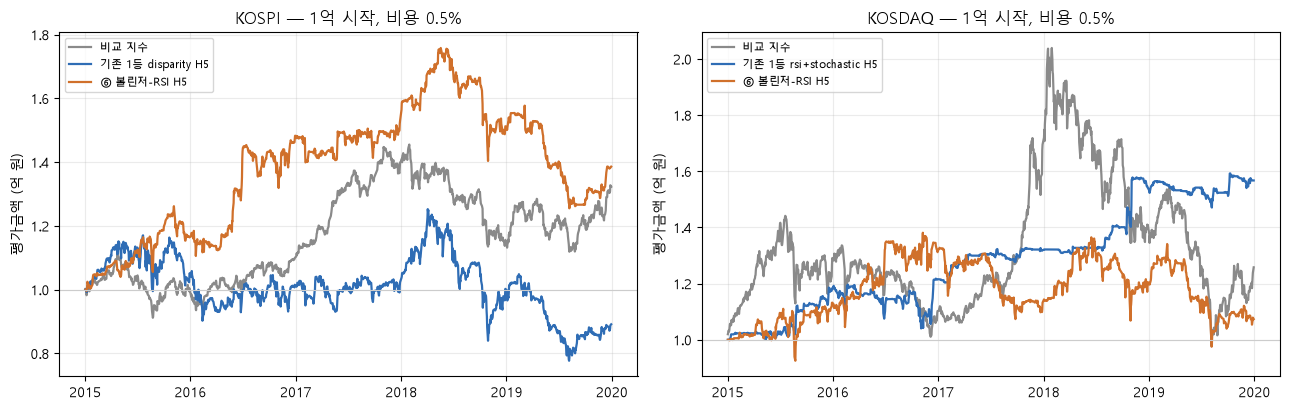

In [10]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

daily = pd.read_csv(K.OUT_DAILY, encoding="utf-8-sig", parse_dates=["date"])
single = pd.read_csv(S4.SINGLE_DAILY, encoding="utf-8-sig", parse_dates=["date"])
ms = B.load_market()
oldtop = R(K.S4.OUT_TOP)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=False)
for ax, mk in zip(axes, ("KOSPI", "KOSDAQ")):
    a = daily[(daily["시장"] == mk) & (daily["신호"] == "c6_boll_rsi_oversold") & (daily["H"] == 5)].set_index("date")["equity"]
    b = oldtop.query("시장 == @mk and 등수 == 1").iloc[0]
    if b["종류"] == "단독":
        d = single
    else:
        d = pd.read_parquet(CB.PARTS / S4.PART_KIND[b["종류"]] / b["신호"] / "portfolio_daily.parquet")
    o = d[(d["시장"] == mk) & (d["신호"] == b["신호"]) & (d["H"] == b["H"])].set_index("date")["equity"]
    ix = ms[(ms["market"] == mk) & ms["date"].dt.year.isin(C.WF_YEARS)].set_index("date")["ret"]
    ixe = 1e8 * (1 + ix).cumprod()
    ax.plot(ixe.index, ixe / 1e8, color="#8a8a8a", lw=1.6, label="비교 지수")
    ax.plot(o.index, o / 1e8, color="#2f6db5", lw=1.6, label=f"기존 1등 {b['신호']} H{b['H']}")
    ax.plot(a.index, a / 1e8, color="#d0702b", lw=1.6, label="⑥ 볼린저-RSI H5")
    ax.axhline(1, color="#cccccc", lw=0.8)
    ax.set_title(f"{mk} — 1억 시작, 비용 0.5%")
    ax.set_ylabel("평가금액 (억 원)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## 9. 정리 (참고용 별개 시험 — 채택 여부는 팀이 정한다)

### 확인한 것
- 8개 조합 × H 3 = 시장마다 24칸을 기존과 **같은 조건**(2015~2019, 비용 0.5%, 1억·20자리, 같은 점수표 계산)으로 계산했다. 테스트 4개 통과, 랜덤·비용 시험에서 다시 계산한 값 = 저장값 (차이 0).
- 대표 조합 1등은 두 시장 모두 **⑥ 볼린저 하단 이탈 + RSI ≤ 30, 5일 보유**. 점수는 기존 1등보다 높다 (코스피 84.3 vs 78.1, 코스닥 83.8 vs 78.9).
- **코스피**: ⑥ 5년 +38.6% → 지수 +32.3% 이김 (기존 1등 disparity H5 −10.9%). 랜덤 매수 1,000번 5해 중 5해 이김 = 통과. 비용 0.25% 면 +77.5%.
  다만 지수를 이긴 해는 3해 (2015·2016·2018), 2017·2019 는 졌다. 번 돈의 대부분이 2015~2016 에서 나왔다.
- **코스닥**: ⑥ 5년 +7.4% → 지수 +25.8% 에 짐 (기존 1등 rsi+stochastic H5 +56.7% 가 훨씬 낫다). 랜덤 5해 중 4해 이김 = 통과 (2017 짐). 비용 0.25% 면 +37.3% 로 지수를 이김 → **비용가정의존**.
- 추세를 따라가는 조합 (①②④⑦⑧) 은 두 시장 모두 5년 −24%~−95% 로 크게 잃었다. ③⑤ 는 거래가 너무 적거나 (⑤ 60~70건) 지수를 못 이겼다.
- SPA (운 빼기): ⑥ 만 봐도 코스피 p=0.82, 코스닥 p=1.00. 기존 칸과 합치면 두 시장 p=0.986 (기존 0.985·0.986 과 거의 같음). → **'운보다 낫다'는 통계 근거는 대표 조합도 없다.** 기존 결과와 같은 처지.
- 시도 수: 시장마다 6,354 → 6,402 (+48줄).

### 확인 못한 것
- 2020년 이후 (규칙상 시험 8 전에는 열지 않음).
- ⑥ 원문의 종목 거르기 (거래대금 50억·시총 상위) 로 한 결과 — 우리 기준 (10억·1,000원) 으로만 했다.
- 파라미터를 바꾼 경우 (RSI 25·35, 볼린저 2.5 등) — 일부러 교과서 값 하나로 고정 (바꾸면 시도 수가 늘고 과적합 위험).
- ⑥ 의 매도 규칙 (예: 볼린저 가운데 선 복귀 때 팔기) — 이번엔 기존과 같게 H일 뒤 팔기만.

### 이상한 것 (설명 붙임)
- **점수는 높은데 수익은 낮다 (코스닥 ⑥)**: 점수는 '거래 하나하나'가 같은 날 아무 종목보다 얼마나 나았는지를 본다. 포트폴리오는 20자리라 신호가 몰리는 날 일부만 사고, 5일마다 사고팔아 비용 0.5% 를 자주 낸다. 그래서 점수 순위와 포트폴리오 수익 순위가 다를 수 있다 (기존 결과에서도 같은 일이 있었다).
- **랜덤 중앙값이 크게 마이너스 (코스피 5년 −32%, 코스닥 −44%)**: ⑥ 신호가 나는 날은 시장이 크게 빠진 날이 많다 (신호 날 중 지수가 200일선 위인 날은 코스피 40%, 코스닥 30% 뿐). 그날 아무 종목이나 사면 크게 잃는다. 따라서 '랜덤 통과' 는 **그 나쁜 날들 안에서 종목을 잘 골랐다**는 뜻이지, 사는 날짜가 좋다는 뜻은 아니다.
- 코스닥 '포트_지수대신쓴해 = 2015': 기존 결과도 모두 같다 (2015년은 코스닥 ETF 상장 전이라 KQ11 지수를 씀, D4 규칙) → 문제 아님.
- 랜덤 시험 걸린 시간 60,381초: 밤사이 컴퓨터가 절전으로 멈춰 있던 시간 포함 (실제 계산은 약 85분) → 결과에는 영향 없음.

## 10. 다음 날 종가 매도 비교 (참고, 11/26)

**왜:** 사용자 11/26 "기간을 짧게 다음 날 종가 매도로 하자. 매도 시점 차이 좀 비교하게 … 이것도 별개의 테스트고 랜덤 1000번은 빼자".

- **성격: 참고용 별개 시험.** 4단계 상위 3개·매도 규칙 단계·시험 8 에는 넣지 않는다. 랜덤 1,000번·SPA 는 하지 않는다.
- 규칙은 **실행 전에** `실험기록.csv` 32번째 줄에 적었다. 결과는 33번째 줄.
- 대상 4칸 (1등만): 코스피 기존 1등 `disparity` H5 · 코스닥 기존 1등 `rsi+stochastic` H5 (W=3) · ⑥ 볼린저-RSI 과매도 H5 두 시장.
  매수 신호와 해마다 고른 세트는 H5 칸 그대로 쓰고 다시 고르지 않는다 → **다른 건 파는 시점뿐**.

| | 5거래일 뒤 시가 (기존) | 다음 날 종가 (새로) |
|---|---|---|
| 매수 | 신호 다음 날(T+1) 시가 | 신호 다음 날(T+1) 시가 |
| 매도 | 매수일 + 5거래일 시가 | 매수 다음 날(T+2) **종가** |
| 그날 못 팔면 (거래정지 등) | 팔 수 있는 첫 날 시가 | 팔 수 있는 첫 날 종가 |
| 팔기 전 상장폐지 | 마지막 종가 | 마지막 종가 |
| 들고 있는 기간 | 약 5거래일 | 약 1거래일 |

- 포트폴리오: 1억·20자리·한 자리 5%, 비용 0.5% (0.25% 는 참고). 종가 매도 날은 그날 시가 매수 뒤에 팔기 때문에 그날 자리는 차 있다.
- 점수: 점수표 계산 그대로, 보유기간 H 자리에 1 을 넣었다 (아래 10-3 조심할 것 참고).
- 코드: `indexbeater/close_exit.py` (엔진·점수표 파일은 고치지 않음). 명령: `python -m indexbeater closeexit --run`.

### 10-1. 테스트 5개

- `test_close_exit_open_same_as_engine`: 새 코드로 '5거래일 뒤 시가'를 돌리면 엔진 결과와 같다
- `test_close_exit_close_rule`: 종가 매도 = 매수 다음 날 종가, 매도 이유 '종가'
- `test_close_exit_halt_moves_sale`: 그날 못 팔면 팔 수 있는 첫 날 종가로 미룬다
- `test_close_exit_no_lookahead`: 뒤 날짜 값을 바꿔도 앞 거래는 그대로 (미래 엿보기 없음)
- `test_close_exit_portfolio_slot_held_on_sale_day`: 파는 날도 그날 자리는 차 있다

맨 아래 줄이 `passed` 이고 `failed` 가 없으면 통과.


In [2]:
import subprocess

r = subprocess.run([sys.executable, "-m", "pytest", "tests/check_period.py", "-k", "close_exit", "--color=no"],
                   capture_output=True, text=True, encoding="utf-8", errors="replace")
print(r.stdout[-1500:] or r.stderr[-1500:])
print("종료 코드:", r.returncode, "(0 = 모두 통과)")


.....                                                                    [100%]
5 passed, 48 deselected in 21.99s

종료 코드: 0 (0 = 모두 통과)


### 10-2. 먼저 점검: 새 코드의 '5거래일 뒤 시가' = 저장된 H5

명령은 종가 매도를 돌리기 전에 두 가지를 먼저 확인하고, 다르면 멈춘다.
1. 새 코드로 만든 대조군(5거래일 뒤 시가) = 점수표 대조군 H5
2. 4칸 각각 새 코드의 '5거래일 뒤 시가' 점수·포트폴리오 = 저장된 H5 값 (49열, 차이 1e-12 이하)

→ 통과하면 두 매도 방식의 차이는 **파는 시점 차이뿐**이라고 말할 수 있다.


In [3]:
import pandas as pd

from indexbeater import close_exit as X

R = lambda p: pd.read_csv(p, encoding="utf-8-sig", float_precision="round_trip")
pct = lambda x: f"{x:+.1%}" if pd.notna(x) else ""

ck = R(X.OUT_CHECK)
print(ck.fillna("").to_string(index=False))
print("\n4칸 모두 저장된 H5 와 같음:", bool(ck["통과"].all()))


    시장    구분                   신호  비교열수        가장큰차이 다른열   통과
 KOSPI  기존1등            disparity    49 9.540979e-17     True
KOSDAQ  기존1등       rsi+stochastic    49 0.000000e+00     True
 KOSPI 대표조합⑥ c6_boll_rsi_oversold    49 0.000000e+00     True
KOSDAQ 대표조합⑥ c6_boll_rsi_oversold    49 0.000000e+00     True

4칸 모두 저장된 H5 와 같음: True


### 10-3. 결과표 (비용 0.5%)

- `Edge` = 거래 1건 수익 − 같은 날 같은 방식으로 아무 종목이나 산 평균 (대조군), 비용 뺀 뒤. `평균수익` = 거래 1건 평균 수익 (비용 뺀 뒤).
- `미룬매매수` = 그날 못 팔아서 뒤로 미룬 거래 수. `평균보유거래일` = 산 날부터 판 날까지 평균 거래일.
- `평균보유종목` = 20자리 중 하루 평균 몇 종목을 들고 있었나 (나머지는 현금).

**조심할 것 — 점수는 두 방식을 직접 비교하면 안 된다.**
점수표는 H 5·10·20 을 위해 만든 것이다. H=1 을 넣으면 `Edge20 = Edge × 20` 이 되어 수익점수가 쉽게 꽉 찬다 (이번엔 5거래일 뒤 시가도 이미 40점 만점이라 차이는 없음).
종가 매도 점수가 오른 건 주로 **안정점수(20일 묶음 t값)** 가 올라서다 (하루만 들고 있어 결과가 덜 흔들림). 그런데 **Edge 원값과 평균수익은 4칸 모두 종가 매도가 더 낮다.**
→ 비교는 `Edge`·`평균수익`·포트폴리오(5년수익·MDD)로 한다.


In [4]:
d = R(X.OUT_COMPARE)
daily = pd.read_csv(X.OUT_DAILY, encoding="utf-8-sig", parse_dates=["date"])
npos = daily.groupby(["시장", "신호", "매도방식", "비용"])["n_pos"].mean().rename("평균보유종목").reset_index()
d = d.merge(npos, on=["시장", "신호", "매도방식", "비용"], how="left")

t = d[d["비용"] == "0.5%"][["시장", "구분", "신호", "매도방식", "점수", "수익점수", "안정점수", "t값", "Edge", "평균수익", "승률",
                           "거래수", "미룬매매수", "상장폐지정산수", "평균보유거래일", "평균보유종목",
                           "포트_5년수익", "지수_5년수익", "지수이긴해수", "포트_MDD"]].copy()
for col in ("평균수익", "포트_5년수익", "지수_5년수익", "포트_MDD"):
    t[col] = t[col].map(pct)
t["승률"] = t["승률"].map(lambda x: f"{x:.1%}")
t["Edge"] = t["Edge"].map(lambda x: f"{x:.4f}")
t["t값"] = t["t값"].round(2)
t["평균보유거래일"] = t["평균보유거래일"].round(2)
t["평균보유종목"] = t["평균보유종목"].round(1)
print(t.to_string(index=False))

print("\n[비용 0.25% 참고] 5년 수익")
w = d.pivot_table(index=["시장", "신호", "지수_5년수익"], columns=["비용", "매도방식"], values="포트_5년수익", aggfunc="first")
w = w.reset_index()
w.columns = [" ".join(c).strip() if isinstance(c, tuple) else c for c in w.columns]
for col in w.columns[2:]:
    w[col] = w[col].map(pct)
print(w.to_string(index=False))

# 결과 숫자로 확인 (아래 정리에 쓴 말이 맞는지)
a = d[d["비용"] == "0.5%"].set_index(["시장", "신호", "매도방식"])
for mk, s in a.index.droplevel(2).unique():
    o, c = a.loc[(mk, s, "5거래일뒤시가")], a.loc[(mk, s, "다음날종가")]
    print(f"{mk:6s} {s:22s} Edge 종가<시가: {c['Edge'] < o['Edge']} | 5년 종가가 나음: {c['포트_5년수익'] > o['포트_5년수익']}")


    시장    구분                   신호    매도방식   점수  수익점수  안정점수   t값   Edge  평균수익    승률  거래수  미룬매매수  상장폐지정산수  평균보유거래일  평균보유종목 포트_5년수익 지수_5년수익  지수이긴해수 포트_MDD
 KOSPI  기존1등            disparity 5거래일뒤시가 78.1  40.0  20.2 1.04 0.0073 +0.7% 52.6% 5635     20        3     5.14    12.3  -10.9%  +32.3%       2 -38.0%
 KOSPI  기존1등            disparity   다음날종가 80.3  40.0  25.0 2.16 0.0054 +0.2% 50.4% 6900      5        1     1.06     4.7  -41.1%  +32.3%       1 -51.1%
KOSDAQ  기존1등       rsi+stochastic 5거래일뒤시가 78.9  40.0  17.0 0.39 0.0089 +1.5% 53.9%  945      3        0     5.68     3.7  +56.7%  +25.8%       3 -13.1%
KOSDAQ  기존1등       rsi+stochastic   다음날종가 80.1  40.0  20.1 1.62 0.0054 +0.7% 55.2% 1071      3        0     1.19     0.9  +13.7%  +25.8%       3 -12.7%
 KOSPI 대표조합⑥ c6_boll_rsi_oversold 5거래일뒤시가 84.3  40.0  21.4 1.28 0.0087 +1.4% 54.4% 3341     14        2     5.12     8.7  +38.6%  +32.3%       3 -28.6%
 KOSPI 대표조합⑥ c6_boll_rsi_oversold   다음날종가 83.0  40.0  24.2 1.83 0.0059 +0.5% 51.3% 3793 

### 10-4. 해마다 + 그림 (비용 0.5%)

1억에서 시작. 회색 = 비교 지수, 파랑 = 5거래일 뒤 시가 (기존), 주황 = 다음 날 종가 (새로). 매수 신호는 같다.


    시장                   신호    매도방식   2015   2016   2017   2018   2019
KOSDAQ              (비교 지수)         +29.1% -14.6% +53.8% -17.0% -10.6%
KOSDAQ c6_boll_rsi_oversold 5거래일뒤시가 +13.2% +15.9% -13.7%  +6.4% -10.9%
KOSDAQ c6_boll_rsi_oversold   다음날종가 +24.4% +15.6%  -9.5%  -1.8%  -8.7%
KOSDAQ       rsi+stochastic 5거래일뒤시가 +18.2%  +2.9%  +8.5% +16.8%  +1.7%
KOSDAQ       rsi+stochastic   다음날종가 +14.9%  -9.0%  +2.7%  +9.8%  -3.6%
 KOSPI              (비교 지수)          -0.1% +10.2% +27.1% -17.3% +14.4%
 KOSPI c6_boll_rsi_oversold 5거래일뒤시가 +16.6% +27.2%  +3.2%  -1.1%  -8.4%
 KOSPI c6_boll_rsi_oversold   다음날종가  +7.5%  +0.2%  -2.1%  -3.2%  -4.9%
 KOSPI            disparity 5거래일뒤시가  +5.2%  -3.6%  +0.9%  -2.0% -11.1%
 KOSPI            disparity   다음날종가 -10.0% -17.3%  -3.9% -10.5%  -8.1%


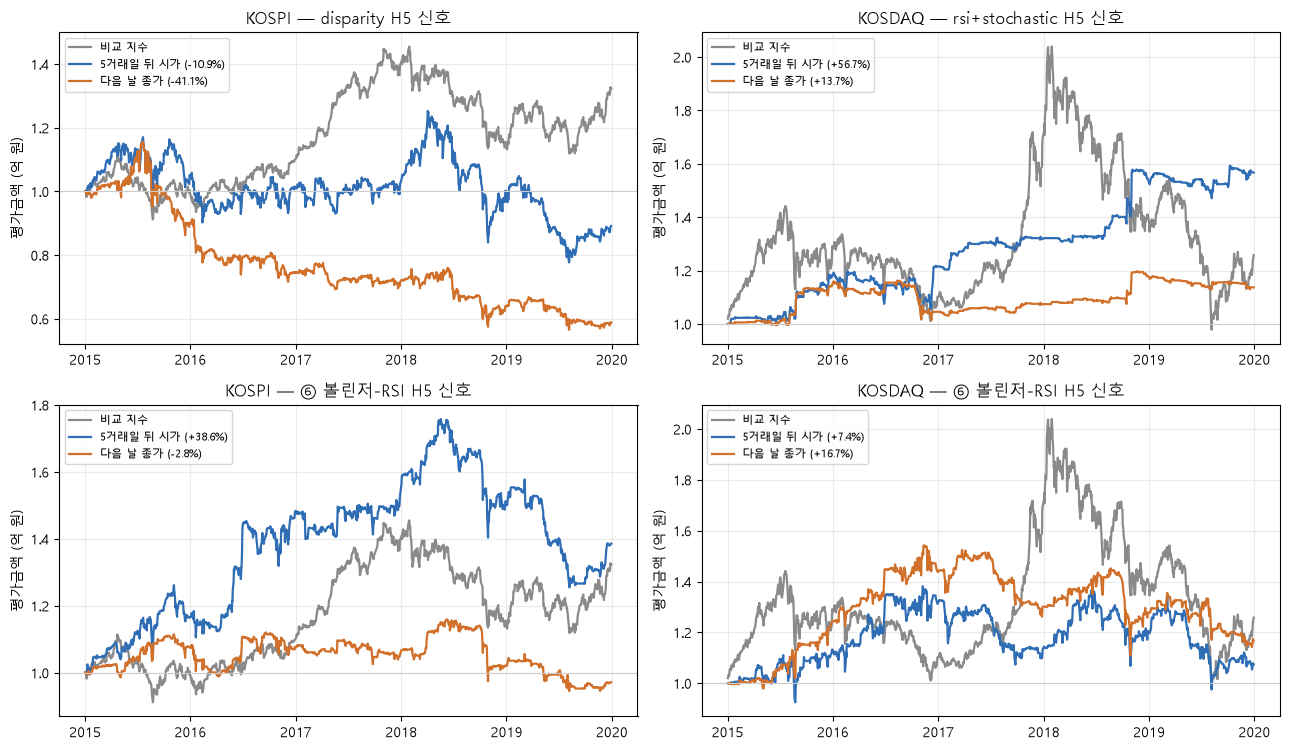

In [5]:
import matplotlib.pyplot as plt

from indexbeater import benchmark as B
from indexbeater import config as C

yrs = C.WF_YEARS
y = d[d["비용"] == "0.5%"][["시장", "신호", "매도방식"] + [f"포트_수익_{i}" for i in yrs]].copy()
y.columns = ["시장", "신호", "매도방식"] + [str(i) for i in yrs]
ix = d.drop_duplicates("시장")[["시장"] + [f"포트_지수수익_{i}" for i in yrs]].copy()
ix.columns = ["시장"] + [str(i) for i in yrs]
ix.insert(1, "신호", "(비교 지수)")
ix.insert(2, "매도방식", "")
yt = pd.concat([y, ix], ignore_index=True).sort_values(["시장", "신호", "매도방식"], kind="stable")
for i in yrs:
    yt[str(i)] = yt[str(i)].map(pct)
print(yt.to_string(index=False))

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
ms = B.load_market()
cells = [("KOSPI", "disparity"), ("KOSDAQ", "rsi+stochastic"), ("KOSPI", "c6_boll_rsi_oversold"), ("KOSDAQ", "c6_boll_rsi_oversold")]
label = {"c6_boll_rsi_oversold": "⑥ 볼린저-RSI"}
fig, axes = plt.subplots(2, 2, figsize=(13, 7.6))
for ax, (mk, s) in zip(axes.ravel(), cells):
    r = ms[(ms["market"] == mk) & ms["date"].dt.year.isin(yrs)].set_index("date")["ret"]
    ax.plot(r.index, (1 + r).cumprod(), color="#8a8a8a", lw=1.6, label="비교 지수")
    for mode, col in (("5거래일뒤시가", "#2f6db5"), ("다음날종가", "#d0702b")):
        e = daily[(daily["시장"] == mk) & (daily["신호"] == s) & (daily["매도방식"] == mode) & (daily["비용"] == "0.5%")].set_index("date")["equity"]
        name = "5거래일 뒤 시가" if mode == "5거래일뒤시가" else "다음 날 종가"
        ax.plot(e.index, e / 1e8, color=col, lw=1.6, label=f"{name} ({e.iloc[-1] / 1e8 - 1:+.1%})")
    ax.axhline(1, color="#cccccc", lw=0.8)
    ax.set_title(f"{mk} — {label.get(s, s)} H5 신호")
    ax.set_ylabel("평가금액 (억 원)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()


### 10-5. 정리 (매도 시점 비교 — 참고용, 채택 여부는 팀이 정한다)

#### 확인한 것
- 새 코드로 돌린 '5거래일 뒤 시가'가 저장된 H5 와 4칸 모두 49열 같다 (가장 큰 차이 1e-16). 테스트 5개 통과. → 두 방식의 차이는 **파는 시점뿐**.
- 비용 0.5% 에서 **4칸 중 3칸은 다음 날 종가 매도가 더 나쁘다.**
  코스피 disparity 5년 −10.9% → −41.1%, 코스닥 rsi+stochastic +56.7% → +13.7%, 코스피 ⑥ +38.6% → −2.8%.
- **코스닥 ⑥ 만 좋아졌다** (+7.4% → +16.7%). 그래도 지수 +25.8% 는 못 이긴다 (0.25% 면 +72.7% 로 이김).
- 거래 1건 평균수익(비용 뺀 뒤)이 4칸 모두 줄었다 (예: 코스피 ⑥ 1.39% → 0.50%). 하루만 들고 있으면 버는 폭은 줄고 비용 0.5% 는 그대로라 **비용에 먹힌다.**
- 거래 수는 10~20% 늘었다 (짧게 들고 있어서 '이미 들고 있어 못 산' 신호가 줄었다).
- 20자리 중 평균 보유 종목 수가 크게 줄었다 (예: 코스피 disparity 12.3 → 4.7개). → 돈 대부분이 현금으로 쉰다.
- 좋아진 점: 코스피 ⑥ 은 MDD 가 −28.6% → −18.5% 로 덜 빠졌다 (5년 수익은 −2.8% 로 나빠짐).

#### 확인 못한 것
- 2020년 이후 (시험 8 전이라 열지 않음).
- 랜덤 1,000번·SPA (사용자 요청대로 뺌) → 종가 매도가 운보다 낫다는 근거는 따로 보지 않았다.
- '팔 수 있는 날' 정의는 엔진 그대로다 (종가가 하한가여도 판다고 봄). 실제로는 하한가 종가에 못 팔 수도 있다.
- 장 마감 동시호가에서 정확히 종가에 판다고 가정했다.

#### 이상한 것 / 조심할 것
- **점수는 두 방식을 직접 비교하면 안 된다.** 종가 매도 점수(80.3·80.1·83.0·84.7)가 3칸에서 더 높지만, 주로 안정점수(t값)가 올라서다. Edge 원값·평균수익·5년 수익은 대부분 더 낮다. 점수표는 H 5·10·20 용으로 만든 것이다.
- 포트폴리오는 둘 다 '한 자리 5%, 20자리' 라서 짧게 들고 있으면 자리가 비고 수익이 작게 나온다. 한 자리 크기를 바꾸면 결과가 달라질 수 있다 (이번 시험 범위 밖, 바꾸려면 규칙부터 다시 적어야 함).

**뜻:** 매도 시점을 '다음 날 종가'로 바꿀 근거는 없다. 4칸 중 3칸에서 기존 '5거래일 뒤 시가'가 낫다.
